# Simple Flower Classifier using an Artificial Neural Network
**Dataset:** Iris (150 flowers, 3 species)  |  **Model:** Feed-forward ANN (TensorFlow/Keras)

Team: Kirish (RA2411056050002) and [Teammate Name] ([Teammate Reg No])

## 1. Load and explore the data

In [1]:
import numpy as np, pandas as pd, json, joblib
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
tf.keras.utils.set_random_seed(42)
iris = load_iris(as_frame=True)
df = iris.frame; df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df.shape); df.head()

I0000 00:00:1790784918.372057     107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790784932.658608     107 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790784939.073509     107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [2]:
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


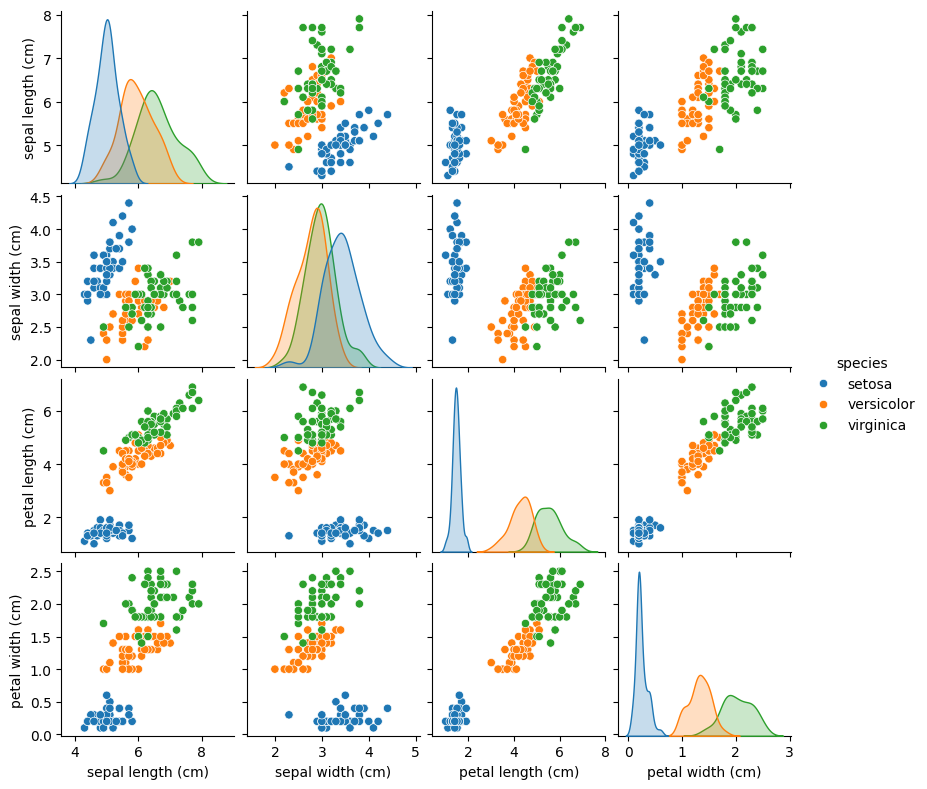

In [3]:
print(df['species'].value_counts())
sns.pairplot(df.drop(columns='target'), hue='species', height=2)
plt.savefig('fig_pairplot.png', dpi=110, bbox_inches='tight'); plt.show()

## 2. Preprocess: split and scale
Stratified 80/20 split; features standardised (mean 0, std 1) using only training statistics.

In [4]:
X, y = iris.data.values, iris.target.values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
print(Xtr.shape, Xte.shape)

(120, 4) (30, 4)


## 3. Build the ANN
Input (4 features) → Dense 16 (ReLU) → Dense 8 (ReLU) → Dense 3 (softmax).

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')])
model.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Train

final train acc 1.000 | val acc 1.000


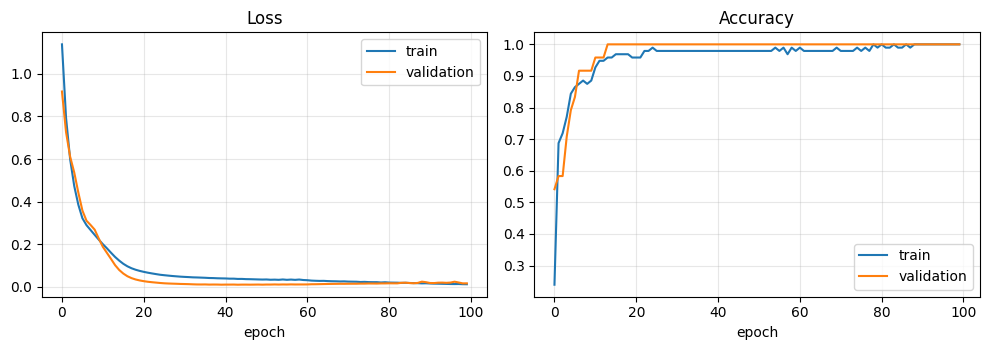

In [6]:
hist = model.fit(Xtr_s, ytr, validation_split=0.2, epochs=100, batch_size=16, verbose=0)
h = hist.history
print(f"final train acc {h['accuracy'][-1]:.3f} | val acc {h['val_accuracy'][-1]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='validation'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='validation'); ax[1].set_title('Accuracy'); ax[1].legend()
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('fig_curves.png', dpi=110); plt.show()

## 5. Evaluate on the unseen test set

Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



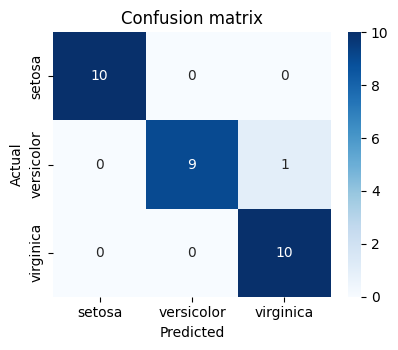

In [7]:
pred = model.predict(Xte_s, verbose=0).argmax(1)
acc = accuracy_score(yte, pred)
print(f'Test accuracy: {acc:.4f}')
print(classification_report(yte, pred, target_names=iris.target_names))
cm = confusion_matrix(yte, pred)
plt.figure(figsize=(4.2, 3.6)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix'); plt.tight_layout(); plt.savefig('fig_cm.png', dpi=110); plt.show()
rep = classification_report(yte, pred, target_names=iris.target_names, output_dict=True)
json.dump({'test_acc': acc, 'val_acc': h['val_accuracy'][-1], 'train_acc': h['accuracy'][-1], 'params': model.count_params(), 'report': rep, 'cm': cm.tolist()}, open('metrics.json', 'w'))

## 6. Save the model for deployment and test a prediction

In [8]:
model.save('iris_model.keras'); joblib.dump(scaler, 'scaler.pkl')
def predict_flower(sl, sw, pl, pw):
    p = model.predict(scaler.transform([[sl, sw, pl, pw]]), verbose=0)[0]
    return iris.target_names[p.argmax()], p
print(predict_flower(5.1, 3.5, 1.4, 0.2))   # expected: setosa
print(predict_flower(6.7, 3.0, 5.2, 2.3))   # expected: virginica

(np.str_('setosa'), array([9.9999845e-01, 1.6066952e-06, 7.7146883e-10], dtype=float32))
(np.str_('virginica'), array([1.0444924e-12, 1.0820788e-08, 1.0000000e+00], dtype=float32))


## 7. Conclusion
A small ANN classifies Iris species with high accuracy. The model and scaler are saved and served through the Streamlit web app (`app.py`).